In [1]:

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
# parameters
mu_values = np.arange(0.05, 1.0001, 0.01)      # Mean Number of Photons/Pulse
alpha = 0.2                                   # Attenuation in fiber in dB/Km
delta_f = 1e3                                 # Linewidth in Hz
d_t = 1e-9                                    # 1/Bit rate
R_b = 1e9                                     # Bit rate
L = np.arange(0, 150.5, 0.5)                  # Length of Fiber
t_B = 0.5                                     # Transmittance of BS
loss_MZI = 1 * 10**(-0.2)                     # 2 dB loss in MZI
theta = 0                                     # Phase difference of two consecutive pulses
eta = 0.2                                     # Efficiency of SPD
Pd_values = np.arange(2e-7, 8.0001e-7, 0.01e-7) # Dark Count Probability
t_d = 10e-9                                   # Dead Time in SPD
t_BSE = 0.8                                   # Transmittance of Eve's BS
f_decoy = 0.2                                 # Probability used to generate the decoy state
duty_cycle_TTL = 0.75                         # Duty cycle of TTL pulses
f = 1.16                                      # Error correction efficiency

X = []
Y = []
Z = []
Color = []

for P_d in Pd_values:

    for mu in mu_values:

        # Phase Noise at LASER
        sigma = np.sqrt(2 * np.pi * delta_f * d_t)

        # Channel transmittance
        eta_channel = 10 ** (-alpha * L / 10)

        Photon_count_after_channel = mu * 10 ** (-alpha * L / 10) * R_b
        
        # DATA LINE

        Photon_count_after_BS = mu * 10 ** (-alpha * L / 10) * R_b * t_B

        Photon_count_after_D_d = Photon_count_after_BS * eta + P_d * R_b

        effective_time_difference_D_d = 1 / Photon_count_after_D_d + t_d

        effective_counts_D_d = (1 / effective_time_difference_D_d) * duty_cycle_TTL
        
        # QBER
        Q_0 = (P_d * R_b - P_d * R_b * (1 - np.exp(-mu * eta_channel * eta * t_B)))/effective_counts_D_d;
        Q = Q_0 * 100;
        
        X.extend(L)
        Y.extend(np.ones_like(L) * mu)
        Z.extend(np.ones_like(L) * P_d * 1e7)
        Color.extend(Q)

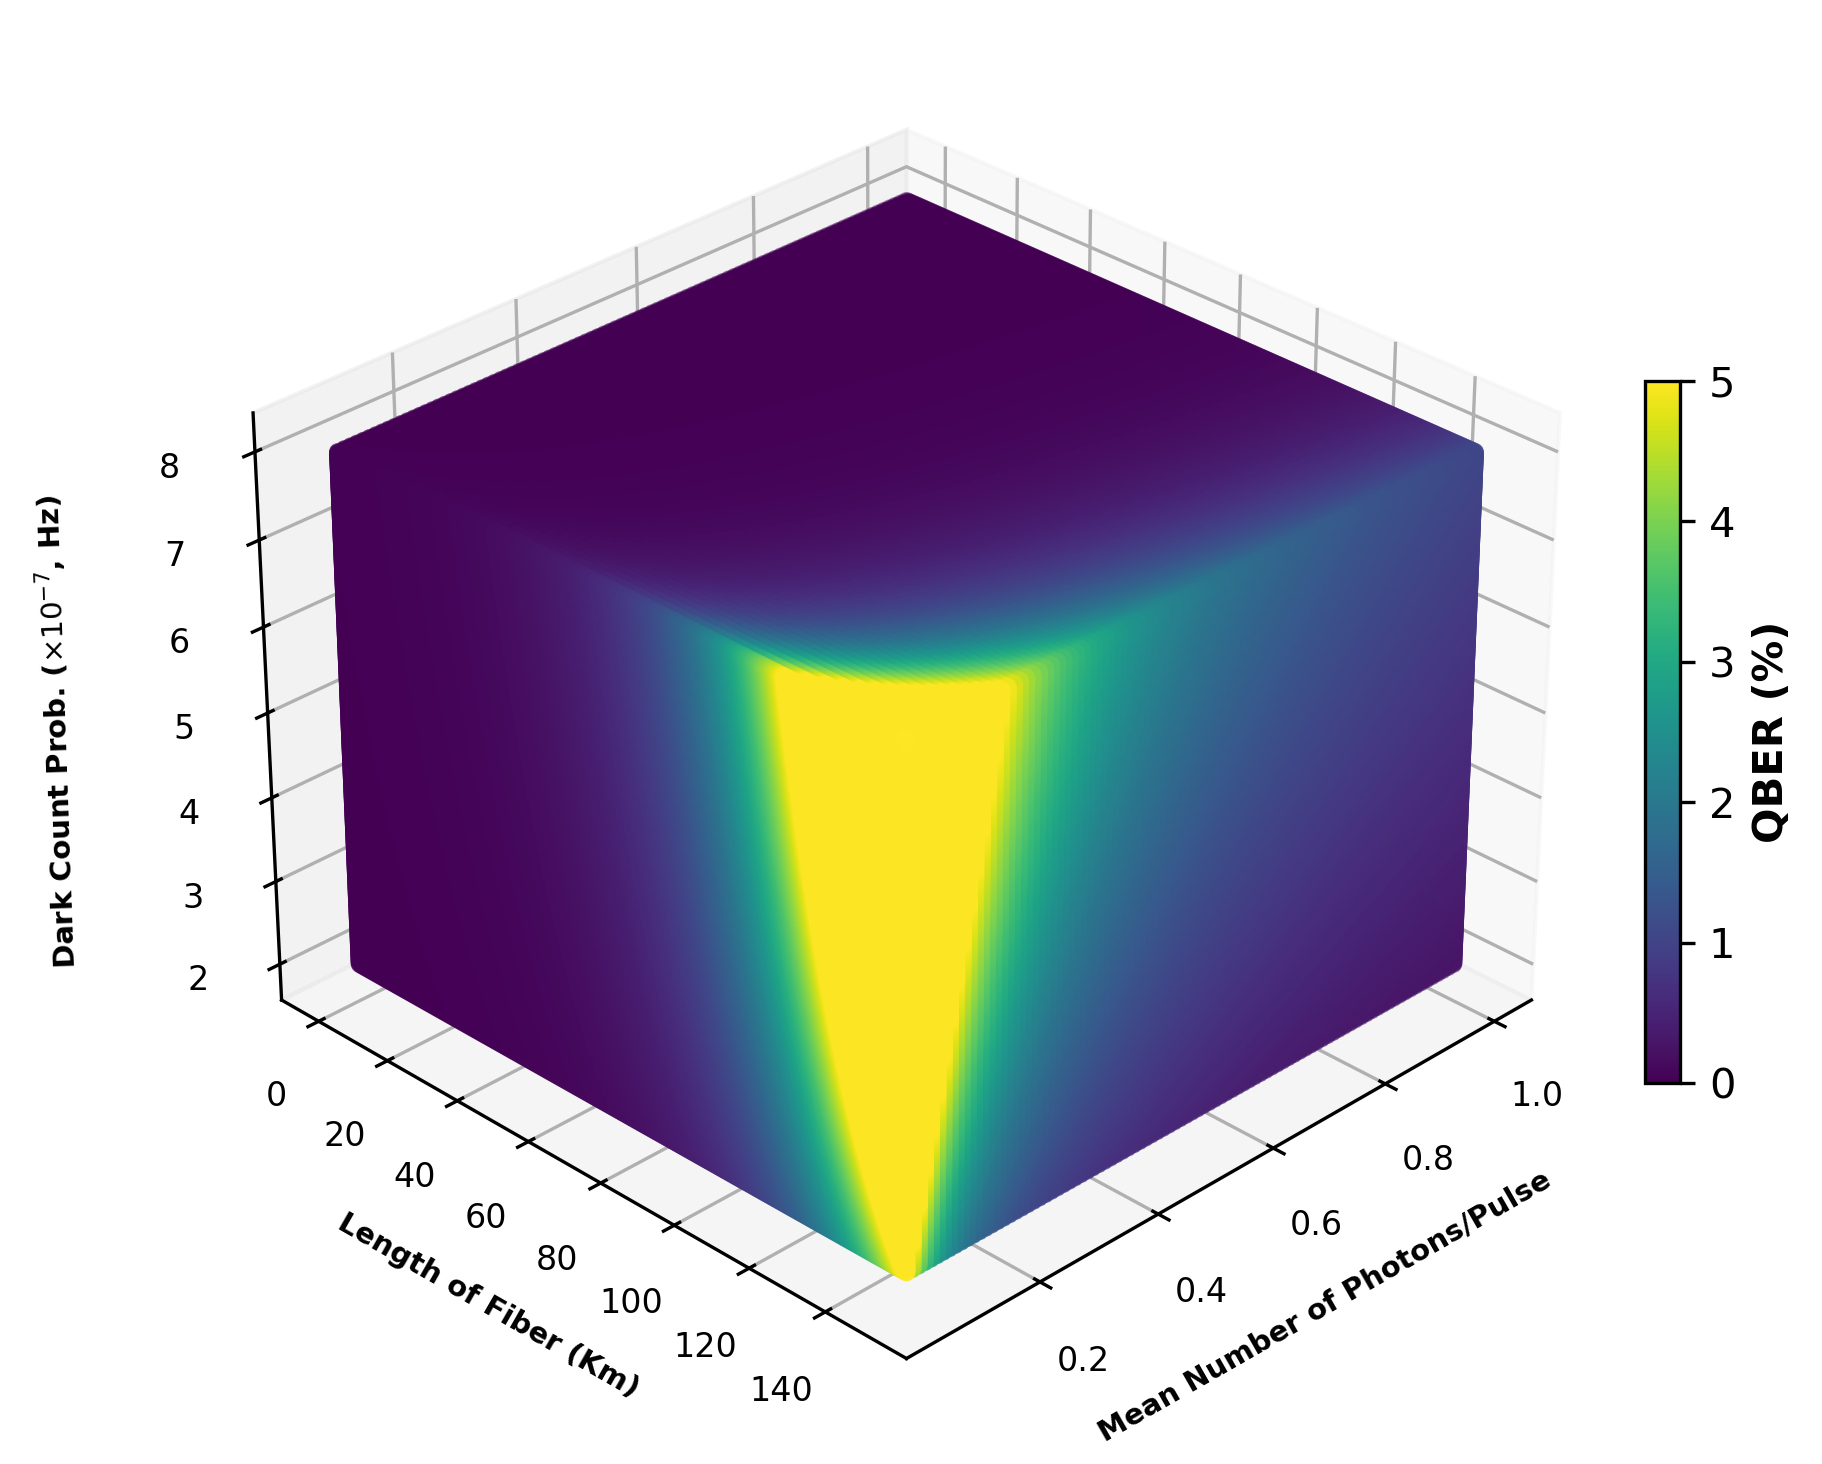

In [2]:
from matplotlib.colors import Normalize
Color = np.asarray(Color)
vmin, vmax = np.percentile(Color, [5, 95])
if np.isclose(vmin, vmax):
    vmin, vmax = Color.min(), Color.max()
fig = plt.figure(figsize=(9, 6.5), dpi=300)
ax = fig.add_axes([0.16, 0.16, 0.68, 0.72], projection="3d")
sc = ax.scatter(
    Y, X, Z,
    c=Color,
    cmap="viridis",                 
    norm=Normalize(vmin=0, vmax=5),
    s=18,
    edgecolors="none"
)
ax.set_xlabel("Mean Number of Photons/Pulse", fontsize=7, labelpad=4, fontweight="bold")
ax.set_ylabel("Length of Fiber (Km)", fontsize=7, labelpad=4, fontweight="bold")
ax.set_zticks(np.arange(2, 9, 1))
ax.invert_xaxis()
ax.view_init(elev=30, azim=45)
ax.tick_params(axis="both", labelsize=8)
ax.tick_params(axis="z", labelsize=8)
fig.text(0.14,0.52,r'Dark Count Prob. ($\times 10^{-7}$, Hz)',rotation=92,fontsize=7,va='center',fontweight='bold')
cbar = fig.colorbar(sc, ax=ax, shrink=0.50, pad=0.03)
cbar.set_label("QBER (%)", fontsize=10, fontweight="bold")
plt.savefig("QBER_plot_L_mu_P_d.png", dpi=300, bbox_inches="tight")
plt.show()